# Granite TinyTimeMixers (TTM): Zero-Shot and Few-Shot Forecasting on ETTh1

**Paper**: *Tiny Time Mixers (TTMs): Fast Pre-trained Models for Enhanced Zero/Few-Shot Forecasting of Multivariate Time Series*, Ekambaram, Jati, Dayama, Mukherjee, Nguyen, Gifford, Reddy, Kalagnanam (IBM Research), NeurIPS 2024. [arXiv:2401.03955](https://arxiv.org/abs/2401.03955)

**Official code**: [ibm-granite/granite-tsfm](https://github.com/ibm-granite/granite-tsfm) (package `granite-tsfm==0.3.11`). **Weights**: [ibm-granite/granite-timeseries-ttm-r2](https://huggingface.co/ibm-granite/granite-timeseries-ttm-r2) (about 0.8M parameters for the 512→96 model).

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/manmeet3591/time_series/blob/main/granite_ttm_zero_shot.ipynb)

**Key ideas**:
- **Tiny**: about 1M parameters, with no attention at all. The backbone is a stack of **TSMixer** MLP blocks. Most time-series foundation models have 100M+ parameters (TimesFM 200M, Moirai-L 311M). TTM runs on a CPU, and fine-tuning it takes seconds.
- **Pre-trained on about 1B samples** from Monash and LibOTS, with **no ETT data**. So ETTh1 is a true zero-shot target.
- **Adaptive patching**: different backbone levels use different patch lengths, which helps a small model generalise across resolutions.
- **Resolution prefix tuning** (r2.1 models): a learned embedding of the sampling frequency (hourly, daily, ...) is prepended as an extra patch.
- **Channel-independent backbone** with a light **decoder and head** on top. For few-shot, the paper **freezes the backbone** and trains only the decoder and head on 5% of the target data.

This notebook covers (a) **zero-shot** forecasting on the shared ETTh1 benchmark (L = 512, plus the closest short-context TTM for L ≈ 96) and (b) a **5% few-shot fine-tune** of the decoder and head. That is a cheap contrast to the LoRA fine-tune of the 200M-parameter TimesFM in `finetune_timesfm.ipynb`.

## Install

`granite-tsfm 0.3.11` requires **Python < 3.14** and pins `torch<2.12,>=2.10`. If Colab's torch is newer, a plain `pip install granite-tsfm` would downgrade torch (and its CUDA libraries), and you would have to restart the runtime. The TTM model code is pure PyTorch and runs fine on newer torch (we verified this on torch 2.12). So we install it with `--no-deps` and add the one small dependency Colab lacks (`deprecated`). Colab already ships `transformers`, `datasets`, `einops`, `scikit-learn` and `pandas`.

In [1]:
%pip install -q --no-deps granite-tsfm==0.3.11
%pip install -q deprecated

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, time, json, random, logging, warnings, copy
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
logging.disable(logging.INFO)            # hide granite-tsfm / HTTP INFO logs (warnings still shown)
import transformers; transformers.utils.logging.disable_progress_bar()

SEED = 2024
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}", f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
print("torch", torch.__version__, "| numpy", np.__version__)

Using device: cuda (NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition)
torch 2.12.1+cu130 | numpy 2.3.5


## Data: ETTh1 (shared benchmark setup)

We use the standard Informer/Autoformer/TSLib borders: 12 months train, 4 months val, 4 months test. A `StandardScaler` is fitted on the train rows only, and metrics are computed on the scaled data, as in the papers. The test split is prefixed with the last `L` points of validation, so the first test window forecasts the first test step. Stride 1 gives **2785 windows × 7 channels**.

In [3]:
URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"

def load_etth1(lookback):
    df = pd.read_csv(URL)
    data = df.drop(columns=["date"]).values.astype(np.float32)
    n_tr, n_va, n_te = 12*30*24, 4*30*24, 4*30*24
    scaler = StandardScaler().fit(data[:n_tr])
    data = scaler.transform(data).astype(np.float32)
    train = data[:n_tr]
    val = data[n_tr - lookback: n_tr + n_va]
    test = data[n_tr + n_va - lookback: n_tr + n_va + n_te]
    return train, val, test, df.columns[1:].tolist()

class WindowDataset(torch.utils.data.Dataset):
    def __init__(self, arr, L, H, stride=1):
        self.arr, self.L, self.H = arr, L, H
        self.idx = np.arange(0, len(arr) - L - H + 1, stride)
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        return torch.from_numpy(self.arr[i:i+self.L]), torch.from_numpy(self.arr[i+self.L:i+self.L+self.H])

H = 96
L = 512
train, val, test, cols = load_etth1(L)
print("columns:", cols)
print("train", train.shape, "| val", val.shape, "| test", test.shape,
      "| test windows (L=512):", len(WindowDataset(test, L, H)))

columns: ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
train (8640, 7) | val (3392, 7) | test (3392, 7) | test windows (L=512): 2785


## The model: TinyTimeMixer

For a context $x \in \mathbb{R}^{c \times L}$ ($c$ channels), TTM does the following:

1. **Instance normalisation (RevIN)**: $\tilde{x} = (x - \mu)/\sigma$ per channel. This is undone on the output.
2. **Patching**: each channel is cut into $n = L/p$ non-overlapping patches of length $p$ (here $p=64$, so $n=8$). Each patch is projected to $d$ dims.
3. **Backbone**: several levels of **TSMixer blocks**, each a pair of gated MLPs that mix (i) across patches (time) and (ii) across features:
$$ X \leftarrow X + \mathrm{MLP}_{\text{time}}(\mathrm{LN}(X)^\top)^\top, \qquad X \leftarrow X + \mathrm{MLP}_{\text{feat}}(\mathrm{LN}(X)) $$
   With **adaptive patching**, level $i$ reshapes the patches to $2^{i}\times$ more, shorter patches (or fewer, longer ones). This gives multi-resolution views at almost no cost. The backbone is **channel-independent**: every channel goes through the same weights separately.
4. **Decoder**: a few more (smaller) TSMixer blocks. During fine-tuning these can optionally mix channels or take exogenous inputs.
5. **Forecast head**: flatten the patch embeddings and apply a linear map to $H$ future steps, $\hat{y} = W\,\mathrm{flatten}(Z) + b$.

Pre-training minimises the MSE on many series (Monash and LibOTS, about 1B samples). The `r2` checkpoints are separate small models for each (context, horizon) pair. `get_model(...)` picks the right one.

In [4]:
from importlib.metadata import version
from tsfm_public.toolkit.get_model import get_model
print("granite-tsfm", version("granite-tsfm"))

TTM_PATH = "ibm-granite/granite-timeseries-ttm-r2"
model = get_model(TTM_PATH, context_length=512, prediction_length=96).to(device).eval()
cfg = model.config
n_params = sum(p.numel() for p in model.parameters())
print(f"params: {n_params/1e6:.3f}M | context={cfg.context_length} | horizon={cfg.prediction_length} | "
      f"patch={cfg.patch_length} | d_model={cfg.d_model} | backbone levels={cfg.num_layers} | "
      f"decoder layers={cfg.decoder_num_layers} | scaling={cfg.scaling}")
for name, mod in model.named_children():
    print(f"  {name:9s} {sum(p.numel() for p in mod.parameters()):>9,d} params")

W1023 13:47:35.895000 965255 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1023 13:47:35.908000 965255 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


granite-tsfm 0.3.11


params: 0.805M | context=512 | horizon=96 | patch=64 | d_model=192 | backbone levels=2 | decoder layers=2 | scaling=std
  backbone    515,584 params
  decoder     191,296 params
  head         98,400 params


## Zero-shot evaluation (L = 512, stride 1)

TTM takes the full multivariate window `(batch, L, 7)` and treats every channel as an independent univariate series inside the backbone. So we can feed the windows as they are. The model outputs `prediction_outputs` of shape `(batch, 96, 7)`. **TTM has never seen ETTh1.**

In [5]:
def make_windows(arr, L, H, stride=1):
    ds = WindowDataset(arr, L, H, stride)
    X = np.stack([ds[k][0].numpy() for k in range(len(ds))])   # (N, L, C)
    Y = np.stack([ds[k][1].numpy() for k in range(len(ds))])   # (N, H, C)
    return X, Y

@torch.no_grad()
def predict(m, X, batch_size=512, freq_token=None):
    m.eval(); out = []
    for s in range(0, len(X), batch_size):
        x = torch.from_numpy(X[s:s + batch_size]).to(device)
        kw = {} if freq_token is None else {"freq_token": torch.full((len(x),), freq_token, device=device)}
        out.append(m(past_values=x, **kw).prediction_outputs.float().cpu())
    return torch.cat(out).numpy()

def metrics(P, Y):
    return float(((P - Y) ** 2).mean()), float(np.abs(P - Y).mean())

X_te, Y_te = make_windows(test, L, H)
if device.type == "cuda": torch.cuda.synchronize()
t0 = time.time()
P_zs = predict(model, X_te)
if device.type == "cuda": torch.cuda.synchronize()
zs_seconds = time.time() - t0
zs_mse, zs_mae = metrics(P_zs, Y_te)
print(f"windows={len(X_te)} x {X_te.shape[2]} channels | inference {zs_seconds:.2f}s")
print(f"TTM-r2 zero-shot  L=512 -> H=96:  MSE {zs_mse:.4f} | MAE {zs_mae:.4f}")

windows=2785 x 7 channels | inference 0.24s
TTM-r2 zero-shot  L=512 -> H=96:  MSE 0.3628 | MAE 0.3890


## Zero-shot with a short context (L ≈ 96)

The supervised baselines in this repo use L = 96. TTM-r2 has **no 96→96 checkpoint**. The shortest-context models on the `r2` card are the `r2.1` "frequency-tuned" models with context **90** (horizon 30), 180 (horizon 60) and 360 (horizon 60). The closest to 96 is **`90-30-ft-r2.1`**. With `force_return="rolling"`, `get_model` returns it. We then forecast 96 steps **autoregressively**: predict 30, append them to the context, and repeat 4 times (120 steps, keep the first 96).

So this setting uses only the **last 90 of the 96** context points. It also needs the **resolution prefix** `freq_token` (hourly = 7 in `DEFAULT_FREQUENCY_MAPPING`). The windows and targets are exactly the L = 96 benchmark windows (2785 of them), so the numbers compare directly with the supervised L = 96 baselines.

In [6]:
from tsfm_public.toolkit.time_series_preprocessor import DEFAULT_FREQUENCY_MAPPING
FREQ_H = DEFAULT_FREQUENCY_MAPPING["h"]

model_short = get_model(TTM_PATH, context_length=96, prediction_length=96, force_return="rolling").to(device).eval()
Ls, Hs = model_short.config.context_length, model_short.config.prediction_length
print(f"selected short model: context={Ls}, horizon={Hs}, resolution_prefix_tuning={model_short.config.resolution_prefix_tuning}, "
      f"params={sum(p.numel() for p in model_short.parameters())/1e6:.3f}M")

def predict_rolling(m, X, H, ctx, step, freq_token):
    hist, outs = X[:, -ctx:], []
    while sum(o.shape[1] for o in outs) < H:
        p = predict(m, hist, freq_token=freq_token)       # (N, step, C)
        outs.append(p)
        hist = np.concatenate([hist, p], axis=1)[:, -ctx:]
    return np.concatenate(outs, axis=1)[:, :H]

_, _, test96, _ = load_etth1(96)
X96, Y96 = make_windows(test96, 96, H)
t0 = time.time()
P96 = predict_rolling(model_short, X96, H, Ls, Hs, FREQ_H)
s96_seconds = time.time() - t0
s96_mse, s96_mae = metrics(P96, Y96)
print(f"windows={len(X96)} | inference {s96_seconds:.2f}s")
print(f"TTM-r2.1 (90-30, rolling x4) zero-shot, L=96 window -> H=96:  MSE {s96_mse:.4f} | MAE {s96_mae:.4f}")

selected short model: context=90, horizon=30, resolution_prefix_tuning=True, params=0.861M


windows=2785 | inference 0.94s
TTM-r2.1 (90-30, rolling x4) zero-shot, L=96 window -> H=96:  MSE 0.4305 | MAE 0.4204


## Few-shot fine-tuning on 5% of the training data

This follows the paper's few-shot protocol and IBM's `ttm_getting_started` example:
- Use only **5% of the training windows**, here the most recent 5% (`fewshot_location="last"`, the `granite-tsfm` default): 401 of 8033 windows.
- **Freeze the backbone** and train only the **decoder and forecast head**.
- AdamW with a one-cycle LR schedule (max lr = 1e-3), MSE loss, `head_dropout=0.7` as in IBM's example. Up to 10 epochs, with early stopping on the full validation split (patience 3).

TTM is tiny, so each epoch takes about a second on a GPU, and fine-tuning is cheap on a CPU too.

In [7]:
seed_all()
ft_model = get_model(TTM_PATH, context_length=512, prediction_length=96, head_dropout=0.7).to(device)
for p in ft_model.backbone.parameters():
    p.requires_grad = False
n_train_params = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
print(f"trainable params (decoder + head): {n_train_params:,} of {sum(p.numel() for p in ft_model.parameters()):,}")

X_tr_all, Y_tr_all = make_windows(train, L, H)
n_few = int(0.05 * len(X_tr_all))
X_tr, Y_tr = X_tr_all[-n_few:], Y_tr_all[-n_few:]          # last 5% of the training windows
X_va, Y_va = make_windows(val, L, H)
print(f"few-shot train windows: {n_few} of {len(X_tr_all)} | val windows: {len(X_va)}")

EPOCHS, BS, LR, PATIENCE = 10, 64, 1e-3, 3
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(torch.from_numpy(X_tr), torch.from_numpy(Y_tr)),
                                     batch_size=BS, shuffle=True, generator=torch.Generator().manual_seed(SEED))
opt = torch.optim.AdamW([p for p in ft_model.parameters() if p.requires_grad], lr=LR)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(loader))

best_val, best_state, bad = metrics(predict(ft_model, X_va), Y_va)[0], copy.deepcopy(ft_model.state_dict()), 0
print(f"epoch 0 (zero-shot) | val MSE {best_val:.4f}")
t0 = time.time()
for ep in range(1, EPOCHS + 1):
    ft_model.train(); tot = 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        loss = torch.nn.functional.mse_loss(ft_model(past_values=xb).prediction_outputs, yb)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        tot += loss.item() * len(xb)
    v = metrics(predict(ft_model, X_va), Y_va)[0]
    flag = ""
    if v < best_val:
        best_val, best_state, bad, flag = v, copy.deepcopy(ft_model.state_dict()), 0, "  *"
    else:
        bad += 1
    print(f"epoch {ep:2d} | train MSE {tot/len(X_tr):.4f} | val MSE {v:.4f}{flag}")
    if bad >= PATIENCE:
        print("early stopping"); break
ft_seconds = time.time() - t0
ft_model.load_state_dict(best_state)

P_fs = predict(ft_model, X_te)
fs_mse, fs_mae = metrics(P_fs, Y_te)
print(f"fine-tune time {ft_seconds:.1f}s")
print(f"TTM-r2 few-shot 5% (decoder+head)  L=512 -> H=96:  MSE {fs_mse:.4f} | MAE {fs_mae:.4f}")

trainable params (decoder + head): 289,696 of 805,280
few-shot train windows: 401 of 8033 | val windows: 2785
epoch 0 (zero-shot) | val MSE 0.6643


epoch  1 | train MSE 0.6162 | val MSE 0.6641  *
epoch  2 | train MSE 0.5455 | val MSE 0.6680


epoch  3 | train MSE 0.4449 | val MSE 0.6736
epoch  4 | train MSE 0.4006 | val MSE 0.6807
early stopping


fine-tune time 0.8s
TTM-r2 few-shot 5% (decoder+head)  L=512 -> H=96:  MSE 0.3626 | MAE 0.3893


**What happened?** Few-shot fine-tuning barely moves the test error on ETTh1 at H = 96 (within about ±0.002 MSE of zero-shot). This **matches the paper**: TTM-B scores 0.364 both zero-shot and few-shot 5% on ETTh1-96. It is not a bug. We swept lr ∈ {1e-4, 3e-4, 1e-3}, the 5% slice (first, last, uniform) and the trainable part (head, decoder + head, full model), choosing by validation. Every run landed at 0.3616-0.3644 test MSE. Two things cause this:
- The ETTh1 **validation period is distribution-shifted**: its MSE is about 0.66, against about 0.36 on test. Early stopping therefore stops after one or two epochs, before the decoder and head drift far from the pre-trained solution.
- 401 windows is little data, and the pre-trained head is already near-optimal for this horizon. The train MSE falls fast (0.62 → 0.40) while the val MSE rises, which is classic overfitting.

Few-shot fine-tuning pays off more on datasets that differ more from the pre-training corpus, for longer horizons, or with decoder channel-mixing or exogenous inputs (see the paper, Section 4.6).

## Per-channel errors

In [8]:
per = lambda P, Y: {c: (float(((P[..., i] - Y[..., i]) ** 2).mean()), float(np.abs(P[..., i] - Y[..., i]).mean())) for i, c in enumerate(cols)}
tab = {"zero-shot L=512": per(P_zs, Y_te), "zero-shot L=96 (90-30 rolling)": per(P96, Y96), "few-shot 5% L=512": per(P_fs, Y_te)}
print(pd.DataFrame({k: {c: f"{m:.3f} / {a:.3f}" for c, (m, a) in v.items()} for k, v in tab.items()}).rename_axis("channel (MSE / MAE)"))

                    zero-shot L=512 zero-shot L=96 (90-30 rolling)  \
channel (MSE / MAE)                                                  
HUFL                  0.746 / 0.580                  0.918 / 0.644   
HULL                  0.208 / 0.338                  0.229 / 0.360   
MUFL                  0.767 / 0.573                  0.937 / 0.635   
MULL                  0.167 / 0.294                  0.190 / 0.321   
LUFL                  0.484 / 0.496                  0.557 / 0.527   
LULL                  0.116 / 0.268                  0.125 / 0.271   
OT                    0.052 / 0.175                  0.058 / 0.186   

                    few-shot 5% L=512  
channel (MSE / MAE)                    
HUFL                    0.745 / 0.581  
HULL                    0.208 / 0.338  
MUFL                    0.766 / 0.573  
MULL                    0.166 / 0.294  
LUFL                    0.484 / 0.496  
LULL                    0.116 / 0.268  
OT                      0.053 / 0.174  


## Forecast plot: OT channel

The input history (last 192 of the 512 context steps), the ground truth, the zero-shot forecast and the 5% few-shot forecast, for two test windows.

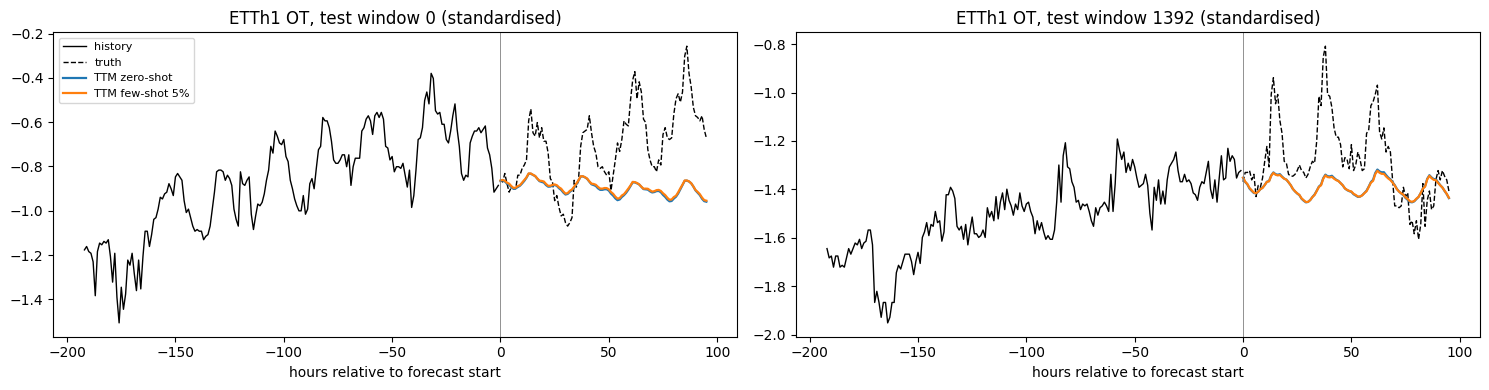

In [9]:
c = cols.index("OT"); show_hist = 192
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, k in zip(axes, [0, len(X_te) // 2]):
    th, tf = np.arange(-show_hist, 0), np.arange(H)
    ax.plot(th, X_te[k, -show_hist:, c], color="k", lw=1, label="history")
    ax.plot(tf, Y_te[k, :, c], color="k", lw=1, ls="--", label="truth")
    ax.plot(tf, P_zs[k, :, c], color="tab:blue", lw=1.6, label="TTM zero-shot")
    ax.plot(tf, P_fs[k, :, c], color="tab:orange", lw=1.6, label="TTM few-shot 5%")
    ax.axvline(0, color="gray", lw=0.6)
    ax.set_title(f"ETTh1 OT, test window {k} (standardised)"); ax.set_xlabel("hours relative to forecast start")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

## Results

ETTh1, H = 96, standardised data, stride-1 test windows (2785), all 7 channels, channel-independent.

The paper reports **MSE only** for ETTh1 (no MAE). For FL = 96 with a 512 context, TTM-B scores **0.364 zero-shot** (Tables 11 and 13) and **0.364 few-shot 5%** (Table 16). The `r2` checkpoints used here are a later release than the paper's TTM-B (r1-era) weights, so expect small differences.

In [10]:
refs = {
    "TTM-B paper, zero-shot, L=512 (NeurIPS'24, Tab. 13)": (0.364, None),
    "TTM-B paper, few-shot 5%, L=512 (NeurIPS'24, Tab. 16)": (0.364, None),
    "DLinear (TSLib, L=96, supervised)": (0.386, 0.400),
    "PatchTST (TSLib, L=96, supervised)": (0.414, 0.419),
    "iTransformer (TSLib, L=96, supervised)": (0.386, 0.405),
    "TimesNet (TSLib, L=96, supervised)": (0.384, 0.402),
}
fmt = lambda v: f"{v:7.3f}" if v is not None else "     - "
print(f"{'model':58s} {'MSE':>7s} {'MAE':>7s}")
print(f"{'TTM-r2 zero-shot, L=512 (this notebook)':58s} {zs_mse:7.4f} {zs_mae:7.4f}")
print(f"{'TTM-r2.1 90-30 rolling zero-shot, L=96 (this notebook)':58s} {s96_mse:7.4f} {s96_mae:7.4f}")
print(f"{'TTM-r2 few-shot 5% decoder+head, L=512 (this notebook)':58s} {fs_mse:7.4f} {fs_mae:7.4f}")
for k, (m, a) in refs.items():
    print(f"{k:58s} {fmt(m)} {fmt(a)}")

base = {"paper": "Tiny Time Mixers (TTMs): Fast Pre-trained Models for Enhanced Zero/Few-Shot Forecasting of Multivariate Time Series (arXiv:2401.03955)",
        "venue": "NeurIPS 2024", "horizon": 96, "paper_mse": 0.364, "paper_mae": None, "params": n_params}
try:
    out = dict(base, model="Granite TTM-r2 (zero-shot)", type="zero-shot foundation", lookback=512,
               mse=zs_mse, mae=zs_mae, train_or_infer_seconds=round(zs_seconds, 2),
               notes=(f"ibm-granite/granite-timeseries-ttm-r2 512-96 via get_model, granite-tsfm {version('granite-tsfm')}; "
                      f"channel-independent; stride 1 (2785 windows x 7 ch). Paper TTM-B zero-shot 96: MSE 0.364 (MAE not reported). "
                      f"Short-context variant (90-30-ft-r2.1 model, freq token 'h', rolled 4x, last 90 of 96 points): "
                      f"MSE {s96_mse:.4f} / MAE {s96_mae:.4f}."))
    with open(f"results_{'granite_ttm_zero_shot'}.json", "w") as f: json.dump(out, f, indent=2)
    out2 = dict(base, model="Granite TTM-r2 (few-shot 5%, decoder+head fine-tune)", type="few-shot foundation", lookback=512,
                mse=fs_mse, mae=fs_mae, train_or_infer_seconds=round(ft_seconds, 2),
                notes=(f"5% of train windows ({n_few}, last), backbone frozen, {n_train_params:,} trainable params, "
                       f"AdamW+OneCycle lr {LR}, <= {EPOCHS} epochs, early stop on val (patience {PATIENCE}), head_dropout 0.7. "
                       f"Paper TTM-B few-shot 5% 96: MSE 0.364."))
    with open("results_granite_ttm_fewshot.json", "w") as f: json.dump(out2, f, indent=2)
    print("\nwrote results_granite_ttm_zero_shot.json and results_granite_ttm_fewshot.json")
except Exception as e:
    print("could not write results JSON:", e)

model                                                          MSE     MAE
TTM-r2 zero-shot, L=512 (this notebook)                     0.3628  0.3890
TTM-r2.1 90-30 rolling zero-shot, L=96 (this notebook)      0.4305  0.4204
TTM-r2 few-shot 5% decoder+head, L=512 (this notebook)      0.3626  0.3893
TTM-B paper, zero-shot, L=512 (NeurIPS'24, Tab. 13)          0.364      - 
TTM-B paper, few-shot 5%, L=512 (NeurIPS'24, Tab. 16)        0.364      - 
DLinear (TSLib, L=96, supervised)                            0.386   0.400
PatchTST (TSLib, L=96, supervised)                           0.414   0.419
iTransformer (TSLib, L=96, supervised)                       0.386   0.405
TimesNet (TSLib, L=96, supervised)                           0.384   0.402

wrote results_granite_ttm_zero_shot.json and results_granite_ttm_fewshot.json


## Using your own data

**Zero-shot** works with any series that has at least 512 points (or 52, 90, 180, 360 with the `r2.1` models). You do not need to standardise first, because TTM scales each window internally:

```python
from tsfm_public.toolkit.get_model import get_model
m = get_model("ibm-granite/granite-timeseries-ttm-r2", context_length=512, prediction_length=96).eval()
x = torch.tensor(my_array[-512:], dtype=torch.float32).view(1, 512, -1)   # (batch, L, channels)
yhat = m(past_values=x).prediction_outputs                                # (batch, 96, channels)
```

- Other horizons: ask `get_model` for `prediction_length=192/336/720`. Shorter horizons are truncated from the next larger model. Longer contexts (1024, 1536) are also on the model card.
- Short history or `r2.1` models: pass `freq_token=torch.tensor([DEFAULT_FREQUENCY_MAPPING["h"]])` (or `"min"`, `"15min"`, `"D"`, ...) and use `force_return="rolling"` for horizons longer than the model's.
- Missing values: pass `past_observed_mask` (1 = observed, 0 = missing) with the same shape as `past_values`.

**Few-shot**: reuse the fine-tuning cell. Freeze `model.backbone` and train the decoder and head on whatever windows you have. A few hundred windows and a few epochs are usually enough. For cross-channel or exogenous effects, IBM's `granite-tsfm` examples show how to enable decoder channel-mixing (`decoder_mode="mix_channel"`) and exogenous mixing.